# ขั้นที่ 1: Sales Insights — อะไรขับเคลื่อนยอดขายของ Walmart

## ภาพรวมของขั้นนี้

| | |
|---|---|
| **คำถาม** | ยอดขายมีรูปแบบอย่างไร และปัจจัยอะไรทำให้ยอดขายขึ้นหรือลง |
| **ทำไมต้องรู้** | ก่อนสร้างโมเดลพยากรณ์ ต้องเข้าใจก่อนว่ายอดขายขึ้นกับอะไร ปัจจัยที่พบในขั้นนี้จะกลายเป็น feature ของโมเดลในขั้นที่ 2 และเป็นข้อเสนอทางธุรกิจในขั้นที่ 4 |
| **ข้อมูล** | ยอดขายรายวันของสินค้า 3,049 รายการ ใน 10 สาขา 3 รัฐ (CA, TX, WI) ช่วง 29 ม.ค. 2011 – 22 พ.ค. 2016 พร้อมราคาและปฏิทินเทศกาล |

## วิธีอ่าน notebook นี้: จากภาพใหญ่ลงไปภาพย่อย

```
1.1 ภาพรวมทั้งบริษัท     ยอดขายรวมเติบโตอย่างไร มีฤดูกาลไหม
      ↓
1.2 แยกตามพื้นที่        รัฐ → สาขา
      ↓
1.3 แยกตามสินค้า         หมวด → แผนก
      ↓
1.4 ปัจจัยที่ขับเคลื่อน    วันในสัปดาห์, เดือน, เทศกาล, SNAP, ราคา
      ↓
1.5 ระดับสินค้ารายตัว     สินค้าขายเร็ว vs ขายช้า
      ↓
1.6 สรุป
```

## เตรียมข้อมูล

ใช้ตารางที่แปลงแล้วจาก `src/data.py` (1 แถว = สินค้า 1 รายการ ในสาขา 1 แห่ง ใน 1 วัน)
ตัดวันที่สินค้ายังไม่วางขายออก (ยังไม่มีราคา) เพื่อไม่ให้ยอด 0 ช่วงนั้นทำให้ค่าเฉลี่ยผิด

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
sys.dont_write_bytecode = True

FIGURES = ROOT / 'reports' / 'figures'
ANALYSIS = ROOT / 'analysis'
sns.set_theme(style='whitegrid')
pd.set_option('display.float_format', '{:,.2f}'.format)


def show(fig, name):
    """แสดงกราฟในหน้านี้ และบันทึกสำเนาไว้ใน reports/figures"""
    fig.tight_layout()
    fig.savefig(FIGURES / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

from src.data import RAW, load_long

In [2]:
df = load_long()
df = df[df['sales'].notna() & df['sell_price'].notna()].reset_index(drop=True)
df['revenue'] = df['sales'] * df['sell_price']

calendar = pd.read_csv(RAW / 'calendar.csv', parse_dates=['date'])
calendar.index = pd.RangeIndex(1, len(calendar) + 1, name='d')
df['date'] = calendar['date'].to_numpy()[df['d'].to_numpy() - 1]

LAST_YEAR = df['d'] > df['d'].max() - 365  # ใช้ดูภาพปัจจุบันของธุรกิจ
print(f'{len(df):,} แถว | {df["date"].min():%d %b %Y} ถึง {df["date"].max():%d %b %Y}')

46,881,677 แถว | 29 Jan 2011 ถึง 22 May 2016


---
## 1.1 ภาพใหญ่: ยอดขายรวมทั้งบริษัท

ดูยอดขายรวมของทั้ง 10 สาขาต่อวัน เส้นสีเทาคือยอดรายวัน เส้นสีน้ำเงินคือค่าเฉลี่ย 28 วัน (ช่วยให้เห็นแนวโน้ม)

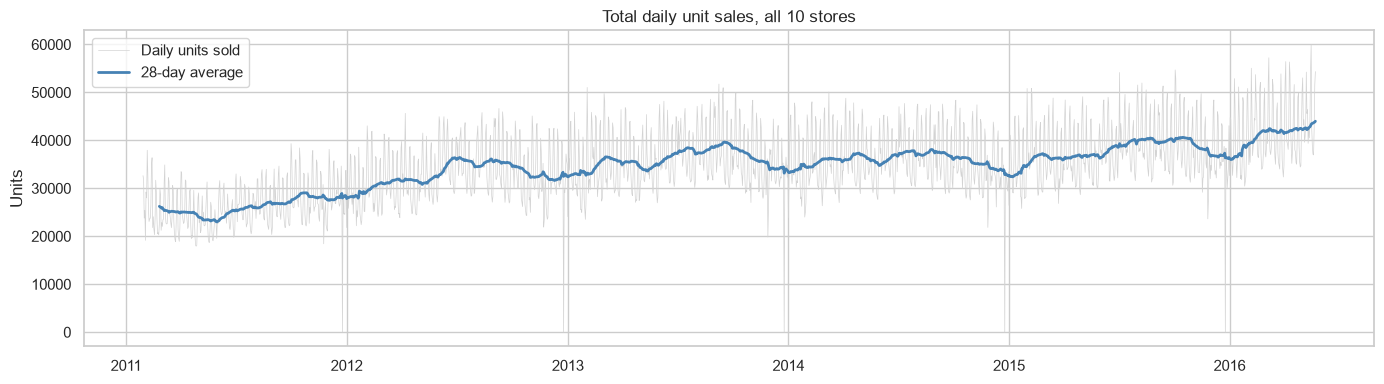

ยอดขายเฉลี่ยต่อวันแต่ละปี (ชิ้น):
date
2011   26,281.00
2012   32,956.00
2013   35,988.00
2014   35,862.00
2015   37,810.00
2016   41,835.00

ยอดขายเฉลี่ยต่อวันปีล่าสุดเทียบปีแรก: +44% (เทียบปีเต็ม 2011 กับ 2015)


In [3]:
daily = df.groupby('date')[['sales', 'revenue']].sum()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(daily.index, daily['sales'], lw=0.5, color='lightgray', label='Daily units sold')
ax.plot(daily.index, daily['sales'].rolling(28).mean(), color='steelblue', lw=2, label='28-day average')
ax.set(title='Total daily unit sales, all 10 stores', ylabel='Units')
ax.legend()
show(fig, '01_1_total_sales')

yearly = daily.resample('YE')['sales'].mean()
print('ยอดขายเฉลี่ยต่อวันแต่ละปี (ชิ้น):')
print(yearly.set_axis(yearly.index.year).round(0).to_string())
print(f"\nยอดขายเฉลี่ยต่อวันปีล่าสุดเทียบปีแรก: +{(yearly.iloc[-2] / yearly.iloc[0] - 1) * 100:.0f}% (เทียบปีเต็ม 2011 กับ 2015)")

**ข้อสังเกต**
- ยอดขายมี **แนวโน้มเติบโต** ต่อเนื่อง
- มี **รูปแบบซ้ำรายสัปดาห์** (เส้นเทาขึ้นลงเป็นฟันเลื่อย)
- มีวันที่ยอดตกเป็นศูนย์ปีละครั้ง คือ **วันคริสต์มาส** ที่ร้านปิด

ต่อไปจะแตกภาพรวมนี้ลงไปดูว่ายอดขายมาจากพื้นที่ไหนบ้าง

---
## 1.2 Drill down: แยกตามพื้นที่ (รัฐ → สาขา)

ใช้ **ยอดขายเป็นเงิน (revenue) ช่วง 365 วันล่าสุด** เพราะสะท้อนความสำคัญทางธุรกิจได้ดีกว่าจำนวนชิ้น

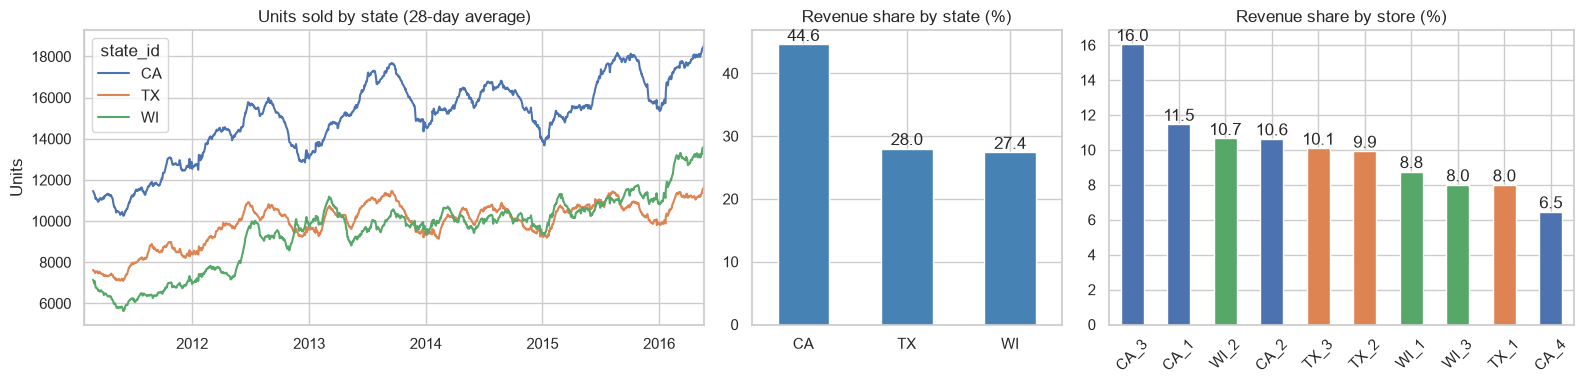

In [4]:
def share(col, data=df[LAST_YEAR]):
    s = data.groupby(col, observed=True)['revenue'].sum().sort_values(ascending=False)
    return s / s.sum() * 100


state_trend = df.groupby(['date', 'state_id'], observed=True)['sales'].sum().unstack().rolling(28).mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={'width_ratios': [2, 1, 1.5]})
state_trend.plot(ax=axes[0], lw=1.5)
axes[0].set(title='Units sold by state (28-day average)', xlabel='', ylabel='Units')

share('state_id').plot.bar(ax=axes[1], color='steelblue', rot=0)
axes[1].set(title='Revenue share by state (%)', xlabel='')
axes[1].bar_label(axes[1].containers[0], fmt='%.1f')

store_share = share('store_id')
colors = store_share.index.str[:2].map({'CA': 'C0', 'TX': 'C1', 'WI': 'C2'})
store_share.plot.bar(ax=axes[2], color=colors, rot=45)
axes[2].set(title='Revenue share by store (%)', xlabel='')
axes[2].bar_label(axes[2].containers[0], fmt='%.1f')
show(fig, '01_2_by_location')

**ข้อสังเกต**
- **CA** เป็นรัฐที่ใหญ่ที่สุด เพราะมี 4 สาขา ส่วน TX และ WI มีรัฐละ 3 สาขา
- ขนาดของแต่ละสาขาต่างกันมาก **แม้จะอยู่ในรัฐเดียวกัน** การวางแผนจึงควรทำแยกรายสาขา ไม่ใช้นโยบายเดียวกันทุกสาขา

---
## 1.3 Drill down: แยกตามสินค้า (หมวด → แผนก)

สินค้ามี 3 หมวด (FOODS, HOUSEHOLD, HOBBIES) แบ่งย่อยเป็น 7 แผนก

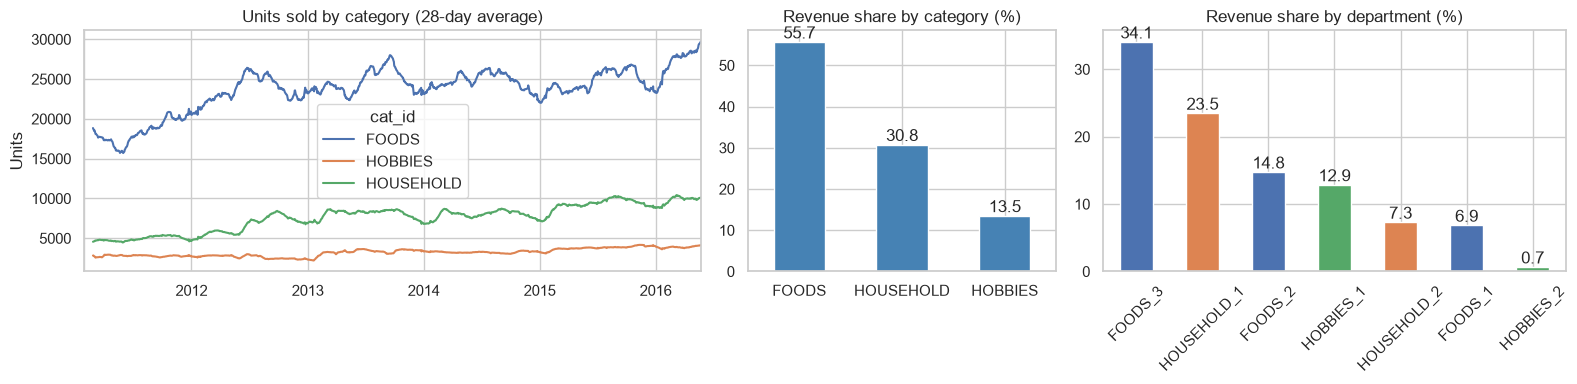

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={'width_ratios': [2, 1, 1.5]})
cat_trend = df.groupby(['date', 'cat_id'], observed=True)['sales'].sum().unstack().rolling(28).mean()
cat_trend.plot(ax=axes[0], lw=1.5)
axes[0].set(title='Units sold by category (28-day average)', xlabel='', ylabel='Units')

share('cat_id').plot.bar(ax=axes[1], color='steelblue', rot=0)
axes[1].set(title='Revenue share by category (%)', xlabel='')
axes[1].bar_label(axes[1].containers[0], fmt='%.1f')

dept_share = share('dept_id')
dept_share.plot.bar(ax=axes[2], color=dept_share.index.str.split('_').str[0].map({'FOODS': 'C0', 'HOUSEHOLD': 'C1', 'HOBBIES': 'C2'}), rot=45)
axes[2].set(title='Revenue share by department (%)', xlabel='')
axes[2].bar_label(axes[2].containers[0], fmt='%.1f')
show(fig, '01_3_by_product')

**ข้อสังเกต**
- **FOODS** ขายได้จำนวนชิ้นมากที่สุดอย่างชัดเจน แต่ถ้าวัดเป็นเงินจะห่างจากหมวดอื่นน้อยลง เพราะสินค้าอาหารราคาต่อชิ้นต่ำกว่า
- แผนก **FOODS_3** (อาหารที่ซื้อเป็นประจำ) เป็นแผนกที่ใหญ่ที่สุด และเป็นกลุ่มที่ควรโฟกัสก่อน

---
## 1.4 ปัจจัยที่ขับเคลื่อนยอดขาย

หลังจากรู้แล้วว่ายอดขายมาจากไหน ต่อไปจะดูว่า **อะไรทำให้ยอดขายเปลี่ยน** โดยดู 4 ปัจจัย

### 1.4.1 ปฏิทิน: วันในสัปดาห์และเดือน

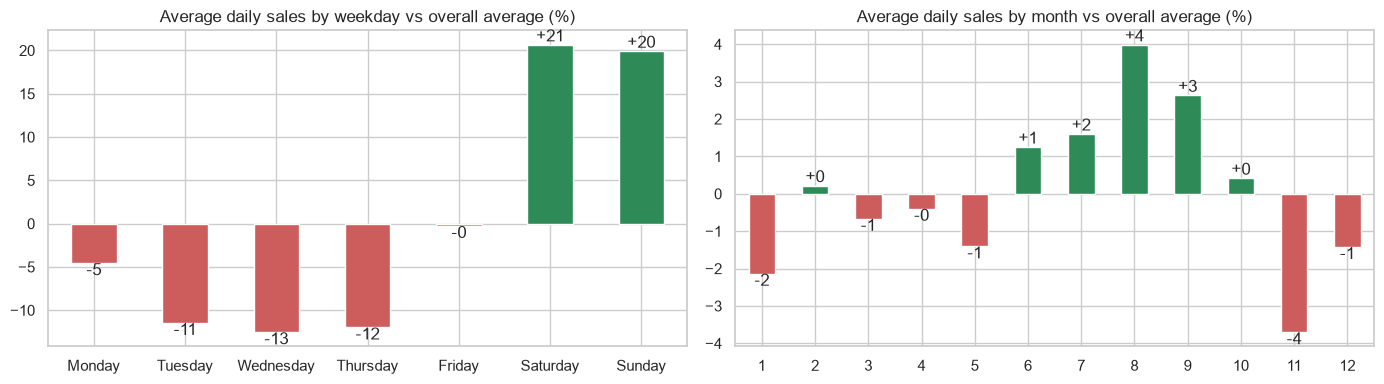

In [6]:
weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_cal = daily.join(calendar.set_index('date')[['weekday', 'month', 'event_name_1', 'event_type_1']])
daily_cal = daily_cal[daily_cal['sales'] > daily['sales'].median() * 0.1]  # ตัดวันคริสต์มาสที่ร้านปิด

weekday_effect = (daily_cal.groupby('weekday')['sales'].mean() / daily_cal['sales'].mean() - 1).reindex(weekday_order) * 100
month_effect = (daily_cal.groupby('month')['sales'].mean() / daily_cal['sales'].mean() - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, effect, title in [(axes[0], weekday_effect, 'weekday'), (axes[1], month_effect, 'month')]:
    effect.plot.bar(ax=ax, color=np.where(effect > 0, 'seagreen', 'indianred'), rot=0)
    ax.set(title=f'Average daily sales by {title} vs overall average (%)', xlabel='')
    ax.bar_label(ax.containers[0], fmt='%+.0f')
show(fig, '01_4_calendar_effect')

**ข้อสังเกต:** เสาร์-อาทิตย์ขายดีกว่าค่าเฉลี่ยประมาณ 20% ส่วนอังคาร-พฤหัสต่ำกว่าค่าเฉลี่ย 11–13% แต่ผลรายเดือนต่างกันแค่ ±4%
แปลว่า **รูปแบบรายสัปดาห์สำคัญกว่าฤดูกาลรายเดือนมาก** สินค้าและพนักงานจึงควรเตรียมให้พร้อมก่อนวันหยุดสุดสัปดาห์

### 1.4.2 เทศกาลและ event

เทียบยอดขายในวัน event กับค่าเฉลี่ยของ **วันเดียวกันในสัปดาห์ก่อนและหลัง** (±1 และ ±2 สัปดาห์) เพื่อตัดผลของวันในสัปดาห์ออก

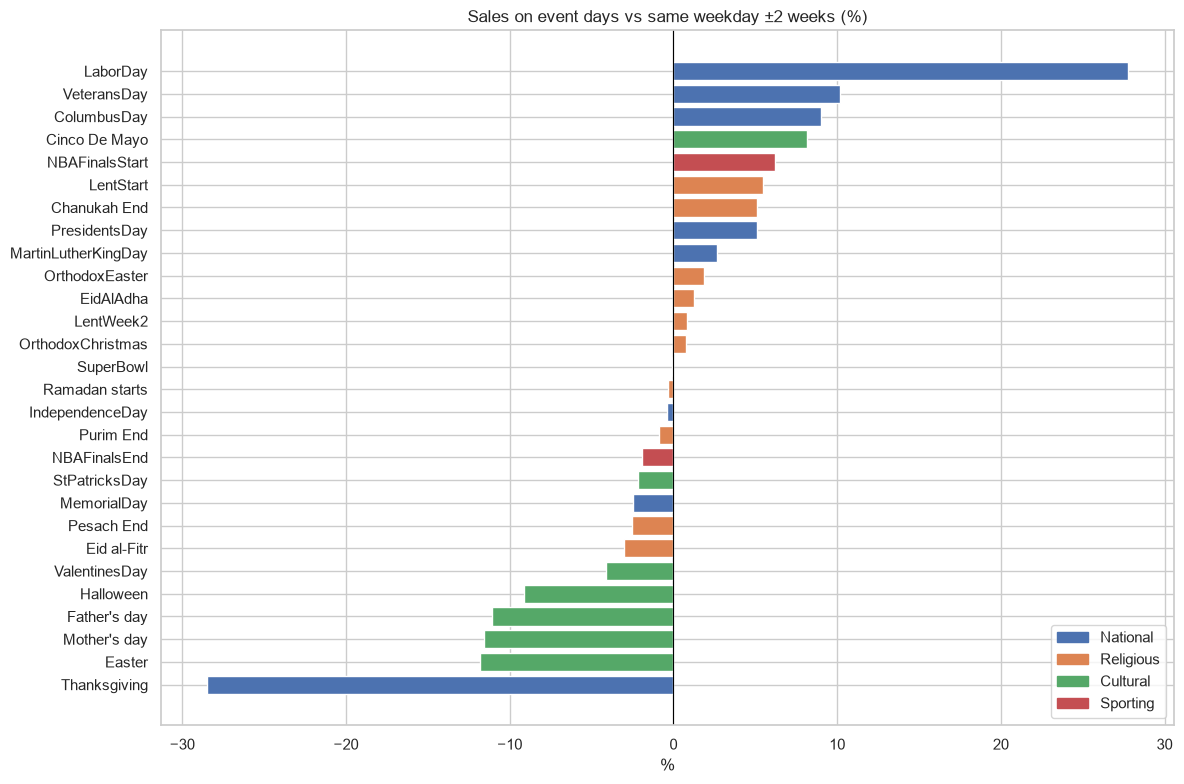

In [7]:
s = daily_cal['sales'].reindex(daily.index)
same_weekday_avg = (s.shift(7) + s.shift(-7) + s.shift(14) + s.shift(-14)) / 4
event_effect = (
    daily_cal.assign(effect=(s / same_weekday_avg - 1) * 100)
    .dropna(subset=['event_name_1', 'effect'])
    .groupby(['event_name_1', 'event_type_1'])['effect'].mean()
    .sort_values()
)

fig, ax = plt.subplots(figsize=(12, 8))
palette = {'National': 'C0', 'Religious': 'C1', 'Cultural': 'C2', 'Sporting': 'C3'}
ax.barh(event_effect.index.get_level_values(0), event_effect.values,
        color=[palette[t] for t in event_effect.index.get_level_values(1)])
ax.axvline(0, color='black', lw=0.8)
ax.set(title='Sales on event days vs same weekday ±2 weeks (%)', xlabel='%')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()], labels=palette.keys(), loc='lower right')
show(fig, '01_4_event_effect')

(ไม่รวมวันคริสต์มาส เพราะร้านปิด)

**ข้อสังเกต:** event ส่งผลได้ทั้งบวกและลบ เช่น Labor Day ยอดขาย **+28%** แต่ Thanksgiving **−28%** ส่วน Easter, Mother's Day และ Father's Day ประมาณ −11% (คนใช้เวลากับครอบครัวหรือร้านเปิดสั้น)
โมเดลจึงต้องรู้ว่าวันไหนเป็น event (เป็น feature ในขั้นที่ 2)

### 1.4.3 วัน SNAP (คูปองอาหารของรัฐ)

SNAP คือโครงการช่วยเหลือค่าอาหารของรัฐบาลสหรัฐฯ แต่ละรัฐจ่ายเงินในวันต่างกัน (เดือนละ 10 วัน)
เทียบยอดขาย **FOODS** เฉลี่ยต่อวันระหว่างวัน SNAP กับวันปกติ แยกตามรัฐ

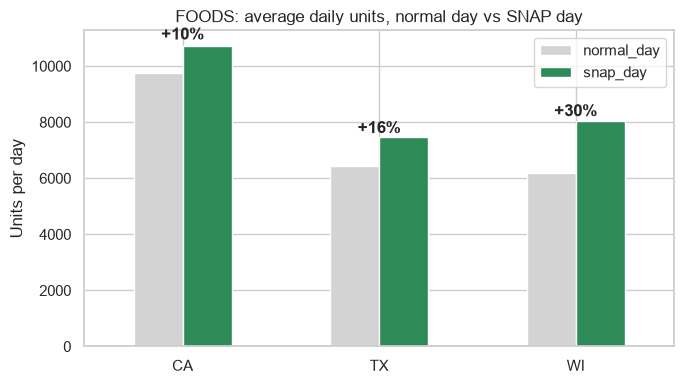

,normal_day,snap_day,uplift_%
state_id,,,
CA,"9,735.97","10,733.38",10.24
TX,"6,453.66","7,462.33",15.63
WI,"6,196.15","8,051.98",29.95


In [8]:
foods_daily = (
    df[df['cat_id'] == 'FOODS']
    .groupby(['state_id', 'd'], observed=True)
    .agg(sales=('sales', 'sum'), snap=('snap', 'first'))
    .reset_index()
)
foods_daily = foods_daily[foods_daily['sales'] > 0]
snap_effect = foods_daily.groupby(['state_id', 'snap'])['sales'].mean().unstack()
snap_effect.columns = ['normal_day', 'snap_day']
snap_effect['uplift_%'] = (snap_effect['snap_day'] / snap_effect['normal_day'] - 1) * 100

fig, ax = plt.subplots(figsize=(7, 4))
snap_effect[['normal_day', 'snap_day']].plot.bar(ax=ax, rot=0, color=['lightgray', 'seagreen'])
for i, (state, row) in enumerate(snap_effect.iterrows()):
    ax.text(i, row['snap_day'] * 1.02, f"+{row['uplift_%']:.0f}%", ha='center', fontweight='bold')
ax.set(title='FOODS: average daily units, normal day vs SNAP day', xlabel='', ylabel='Units per day')
show(fig, '01_4_snap_effect')
snap_effect

**ข้อสังเกต:** วัน SNAP ทำให้ยอดอาหารสูงขึ้นอย่างชัดเจนในทุกรัฐ และแต่ละรัฐเพิ่มขึ้นไม่เท่ากัน
นี่คือโอกาสทางธุรกิจที่วางแผนล่วงหน้าได้ เพราะ **รู้วัน SNAP ล่วงหน้า**

### 1.4.4 ราคาและโปรโมชัน

เทียบยอดขายของ **สินค้าเดียวกัน ในสาขาเดียวกัน** ระหว่างช่วงที่ลดราคา (ราคาต่ำกว่าราคาปกติ ≥ 5%) กับช่วงราคาปกติ
ราคาปกติ = ราคาสูงสุดของสินค้านั้นในสาขานั้น

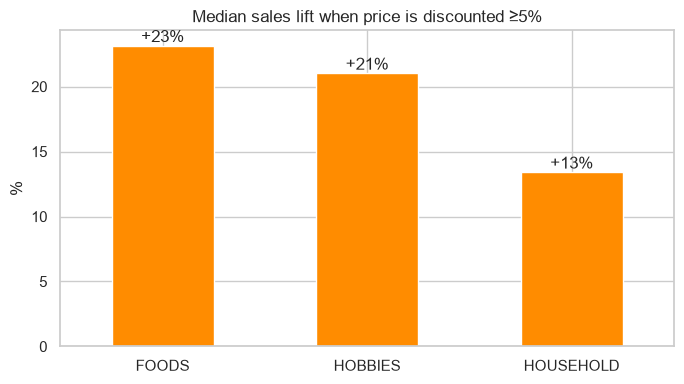

,items_with_discount,median_sales_lift_%
cat_id,,
FOODS,10193,23.16
HOBBIES,3054,21.03
HOUSEHOLD,5017,13.42


In [9]:
regular_price = df.groupby(['item_id', 'store_id'], observed=True)['sell_price'].transform('max')
df['discount'] = df['sell_price'] / regular_price <= 0.95

by_series = df.groupby(['cat_id', 'item_id', 'store_id', 'discount'], observed=True)['sales'].mean().unstack().dropna()
by_series = by_series[by_series[False] > 0]
by_series['lift_%'] = (by_series[True] / by_series[False] - 1) * 100

price_effect = pd.DataFrame({
    'items_with_discount': by_series.groupby('cat_id', observed=True).size(),
    'median_sales_lift_%': by_series.groupby('cat_id', observed=True)['lift_%'].median(),
})

fig, ax = plt.subplots(figsize=(7, 4))
price_effect['median_sales_lift_%'].plot.bar(ax=ax, color='darkorange', rot=0)
ax.bar_label(ax.containers[0], fmt='+%.0f%%')
ax.set(title='Median sales lift when price is discounted ≥5%', xlabel='', ylabel='%')
show(fig, '01_4_price_effect')
price_effect

**ข้อสังเกต:** เมื่อลดราคา ยอดขายเพิ่มขึ้นในทุกหมวด ราคาจึงเป็นอีกปัจจัยที่ต้องใส่ให้โมเดล

> หมายเหตุ: ตัวเลขนี้เป็นความสัมพันธ์ ไม่ใช่เหตุและผลโดยตรง เพราะช่วงลดราคาอาจตรงกับช่วงที่มีปัจจัยอื่นด้วย

---
## 1.5 Drill down ถึงระดับสินค้า: ขายเร็ว vs ขายช้า

ลงไปดูระดับเล็กที่สุดคือ **สินค้า 1 รายการใน 1 สาขา** (มีทั้งหมด 30,490 รายการ)
แบ่งกลุ่มตามสัดส่วนวันที่ขายได้ 0 ชิ้นในช่วง 365 วันล่าสุด

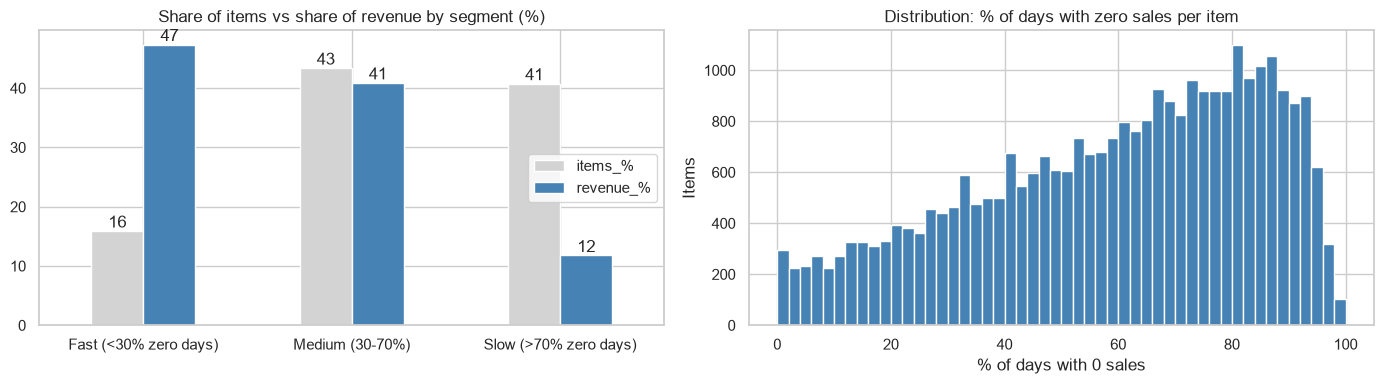

,items,items_%,revenue_%
segment,,,
Fast (<30% zero days),4845,15.89,47.35
Medium (30-70%),13222,43.37,40.88
Slow (>70% zero days),12423,40.74,11.77


In [10]:
recent = df[LAST_YEAR]
keys = ['cat_id', 'item_id', 'store_id']
series = pd.DataFrame({
    'zero_share': (recent['sales'] == 0).groupby([recent[k] for k in keys], observed=True).mean(),
    'revenue': recent.groupby(keys, observed=True)['revenue'].sum(),
})
SEGMENTS = ['Fast (<30% zero days)', 'Medium (30-70%)', 'Slow (>70% zero days)']
series['segment'] = pd.cut(series['zero_share'], [0, 0.3, 0.7, 1], include_lowest=True, labels=SEGMENTS)

segments = series.groupby('segment', observed=True).agg(items=('revenue', 'size'), revenue=('revenue', 'sum'))
segments['items_%'] = segments['items'] / segments['items'].sum() * 100
segments['revenue_%'] = segments['revenue'] / segments['revenue'].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
segments[['items_%', 'revenue_%']].plot.bar(ax=axes[0], rot=0, color=['lightgray', 'steelblue'])
axes[0].set(title='Share of items vs share of revenue by segment (%)', xlabel='')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='%.0f')
axes[1].hist(series['zero_share'] * 100, bins=50, color='steelblue')
axes[1].set(title='Distribution: % of days with zero sales per item', xlabel='% of days with 0 sales', ylabel='Items')
show(fig, '01_5_item_segments')
segments[['items', 'items_%', 'revenue_%']]

ตัวอย่างยอดขายรายวัน 90 วันล่าสุดของสินค้า 1 ตัวจากแต่ละกลุ่ม

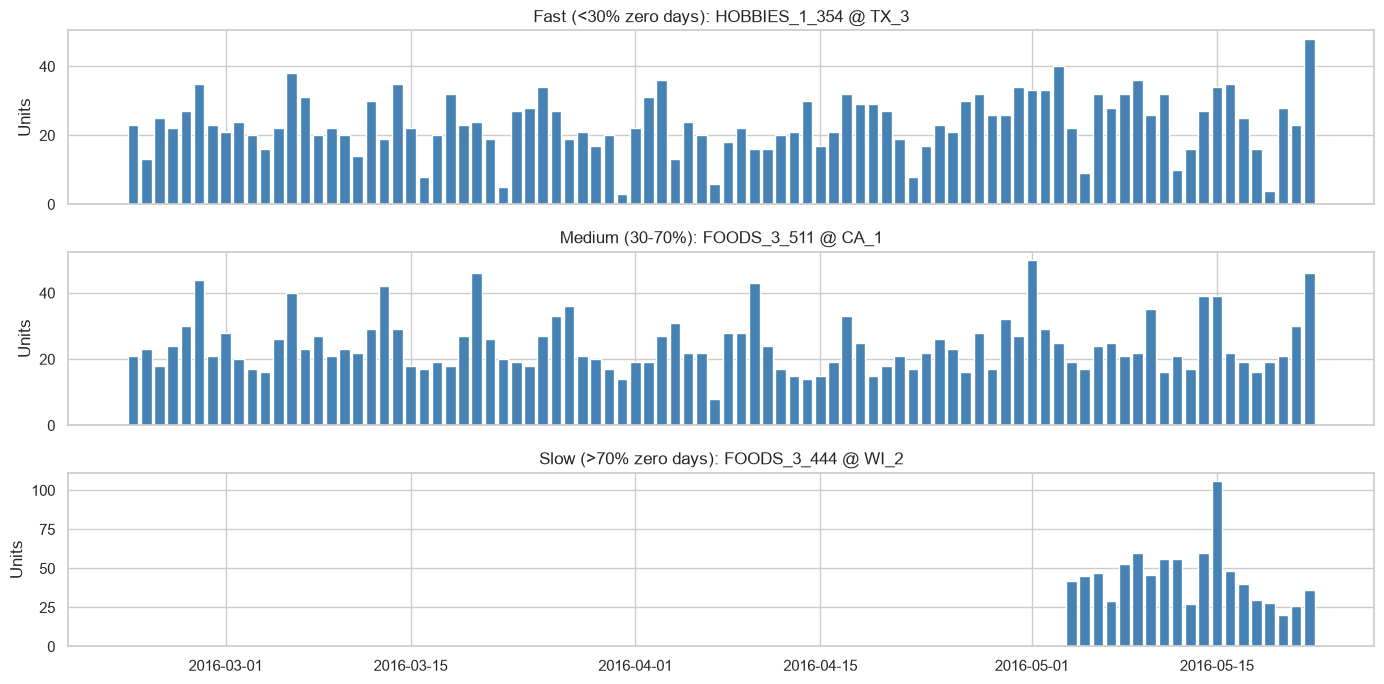

In [11]:
examples = series.groupby('segment', observed=True)['revenue'].idxmax()
last_90 = df[df['d'] > df['d'].max() - 90]

fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
for ax, (segment, (cat, item, store)) in zip(axes, examples.items()):
    one = last_90[(last_90['item_id'] == item) & (last_90['store_id'] == store)]
    ax.bar(one['date'], one['sales'], color='steelblue')
    ax.set(title=f'{segment}: {item} @ {store}', ylabel='Units')
show(fig, '01_5_item_examples')

**ข้อสังเกต**
- สินค้าจำนวนมากเป็น **สินค้าขายช้า** คือขายได้ 0 ชิ้นเกือบทุกวัน แต่สินค้ากลุ่มนี้สร้างรายได้เพียงส่วนน้อย
- สินค้าขายเร็วจำนวนไม่มากสร้างรายได้เกือบครึ่ง
- ยอดขายที่เป็น 0 บ่อยทำให้พยากรณ์ยาก ในขั้นที่ 2 จึงเลือกใช้ loss แบบ **Tweedie** ที่ออกแบบมาสำหรับข้อมูลลักษณะนี้

---
## 1.6 สรุปขั้นที่ 1

| ระดับ | สิ่งที่พบ | นำไปใช้ต่อ |
|---|---|---|
| **ภาพรวม** | ยอดขายเฉลี่ยต่อวันเพิ่มจากประมาณ 26,300 ชิ้น (2011) เป็น 37,800 ชิ้น (2015) หรือ **+44%** และมีรูปแบบซ้ำรายสัปดาห์ชัดเจน | feature ยอดขายในอดีต (lag, rolling) |
| **พื้นที่** | CA 44.6%, TX 28.0%, WI 27.4% ของรายได้ สาขาใหญ่สุด (CA_3, 16.0%) ใหญ่กว่าสาขาเล็กสุด (CA_4, 6.5%) ประมาณ 2.5 เท่าแม้อยู่รัฐเดียวกัน | feature รหัสสาขา/รัฐ, วางแผนแยกรายสาขา |
| **สินค้า** | FOODS 55.7%, HOUSEHOLD 30.8%, HOBBIES 13.5% แผนก FOODS_3 แผนกเดียวคิดเป็น 34.1% | โฟกัส FOODS เป็นลำดับแรก (pilot ในขั้นที่ 4) |
| **วันในสัปดาห์** | เสาร์-อาทิตย์ +20% ส่วนกลางสัปดาห์ −11 ถึง −13% | feature `wday`, เตรียมสต็อกและพนักงานก่อนวันหยุด |
| **Event** | Labor Day +28%, Thanksgiving −28%, Easter/Mother's/Father's Day ประมาณ −11% | feature event, วางแผนตามปฏิทินเทศกาล |
| **SNAP** | ยอด FOODS ในวัน SNAP สูงขึ้น **CA +10%, TX +16%, WI +30%** | feature `snap`, เติมสต็อกอาหารก่อนวัน SNAP |
| **ราคา** | ลดราคา ≥ 5% ยอดขายเพิ่มขึ้น (มัธยฐาน) FOODS +23%, HOBBIES +21%, HOUSEHOLD +13% | feature ราคา 3 ตัว |
| **สินค้ารายตัว** | **41%** ของรายการเป็นสินค้าขายช้า (ขาย 0 ชิ้นมากกว่า 70% ของวัน) แต่สร้างรายได้แค่ **12%** ขณะที่สินค้าขายเร็ว 16% สร้างรายได้ 47% | ใช้ Tweedie loss, ใช้นโยบายสต็อกแยกตามกลุ่ม |

**ข้อสรุป:** ยอดขายมีรูปแบบที่คาดการณ์ได้ (รายสัปดาห์, event, SNAP, ราคา) และข้อมูลเหล่านี้รู้ล่วงหน้าได้ทั้งหมด จึงนำมาใช้พยากรณ์ในขั้นที่ 2 ได้